# Heart Rate Estimation from a Smartphone Video of a Finger

Photoplethysmography (PPG) from a phone-camera video: extract a brightness signal from the video, then estimate heart rate with the FFT.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

## Part 1 – Extracting the PPG signal from the video

**Step 1 – Open the video.** We open the video with OpenCV and read its frame rate. The frame rate is the sampling rate of our signal, because every frame gives one sample.

In [2]:
VIDEO_PATH = "data/video_of_finger.MOV"

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise FileNotFoundError(f"Could not open {VIDEO_PATH}")

fs_video = cap.get(cv2.CAP_PROP_FPS)                  # frames per second = sampling rate (Hz)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))     # total number of frames
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f"Frame rate: {fs_video:.3f} frames per second")
print(f"Number of frames: {n_frames}")
print(f"Frame size: {width} x {height} pixels")
print(f"Duration: {n_frames / fs_video:.1f} s")

Frame rate: 29.978 frames per second
Number of frames: 1852
Frame size: 1080 x 1920 pixels
Duration: 61.8 s


**Step 2 – Mean grayscale value of each frame.** We read the video one frame at a time, convert each frame to grayscale and take the mean of all its pixels. Each heartbeat changes how much light passes through the finger, so this mean brightness changes with the pulse. This gives one number per frame: our PPG signal.

In [3]:
gray_means = []                                       # one value per frame

while True:
    ret, frame = cap.read()                           # ret is False when there are no frames left
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)    # colour frame -> grayscale
    gray_means.append(gray.mean())                    # average brightness of the whole frame

cap.release()
gray_means = np.array(gray_means)

print(f"Frames read: {len(gray_means)}")
print(f"First 5 values: {np.round(gray_means[:5], 2)}")

Frames read: 1852
First 5 values: [55.88 55.68 54.28 52.94 52.02]


We turn frame numbers into time in seconds (frame number ÷ frame rate) and plot the mean grayscale value over time.

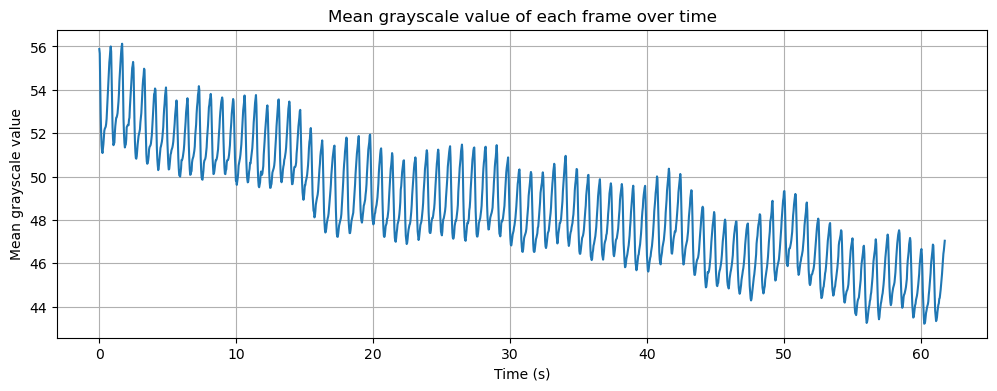

In [4]:
t_video = np.arange(len(gray_means)) / fs_video        # time of each frame in seconds

plt.figure(figsize=(12, 4))
plt.plot(t_video, gray_means)
plt.xlabel("Time (s)")
plt.ylabel("Mean grayscale value")
plt.title("Mean grayscale value of each frame over time")
plt.grid(True)
plt.show()

## Part 2 – Heart rate from the video signal

Approach: we first build and test the heart-rate functions on a **synthetic signal with a known heart rate**, so we can check that they recover the correct answer. We then apply the same functions to the real video signal.

**Step 1 – Synthetic test signal.** We create a 60 s signal sampled at 30 Hz that contains the three components we expect in a real PPG recording: a periodic pulse at a known heart rate (72 bpm), a slow baseline drift, and random noise. Because the true heart rate is known, this lets us verify each processing step.

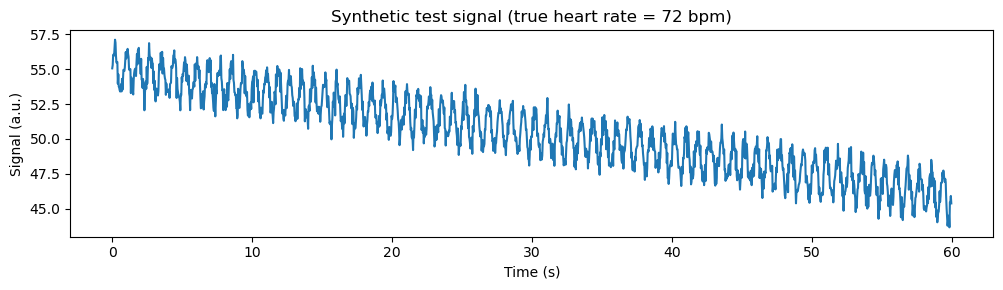

In [5]:
# Synthetic test signal with a KNOWN heart rate, used to check our functions before using real data
fs_test = 30.0                            # sampling rate (Hz), similar to a phone camera
t_test = np.arange(0, 60, 1 / fs_test)    # 60 s of time stamps: 0, 1/30, 2/30, ...
true_hr_bpm = 72                          # the answer our method should recover
f_heart = true_hr_bpm / 60                # 72 beats per minute = 1.2 beats per second (Hz)

rng = np.random.default_rng(seed=0)                      # fixed seed -> same random noise every run
pulse = 1.5 * np.sin(2 * np.pi * f_heart * t_test)       # heartbeat component
drift = 55 - 0.15 * t_test                               # slow downward drift (e.g. finger pressure, camera heating)
noise = 0.5 * rng.standard_normal(len(t_test))           # random measurement noise
test_signal = drift + pulse + noise

plt.figure(figsize=(10, 3))
plt.plot(t_test, test_signal)
plt.xlabel("Time (s)")
plt.ylabel("Signal (a.u.)")
plt.title(f"Synthetic test signal (true heart rate = {true_hr_bpm} bpm)")
plt.tight_layout()
plt.show()